# Week 2 — Regularized Linear Regression: Ridge, Lasso, and Elastic Net

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Question for this notebook:** When the interest-rate regression from Week 1 is given many more candidate terms (all squares and pairwise interactions of the numeric predictors), does regularization improve out-of-sample accuracy, and which terms survive?

**Data recap (built in the Week 1 notebook).** Accepted LendingClub loans issued 2007–2015 whose full term ended by the December 2018 data cutoff and whose final status is known (fully paid or charged off). A stratified sample was split once into 70% training and 30% test with a fixed seed. Every notebook uses the same split, and the test rows are touched only for final evaluation.

**Target:** `int_rate`, LendingClub's assigned interest rate (%), the lender's own price for risk. `grade`, `sub_grade`, and `installment` are excluded because they are set from, or computed with, the rate itself (see Week 1).

**Methods**

| Model | Penalty | Effect |
|---|---|---|
| OLS | none | unbiased but high-variance with many correlated terms |
| Ridge | $\alpha\sum\beta_j^2$ | shrinks all coefficients toward 0; handles correlated predictors |
| Lasso | $\alpha\sum\lvert\beta_j\rvert$ | shrinks some coefficients exactly to 0 (feature selection) |
| Elastic net | $\alpha[\rho\sum\lvert\beta_j\rvert + \tfrac{1-\rho}{2}\sum\beta_j^2]$ | mixes both; keeps groups of correlated predictors together |

Penalties depend on coefficient size, so all predictors are **standardized** first (inside the pipeline, fitted on training folds only). The penalty strength α is chosen by **5-fold cross-validation on the training set**.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, Ridge, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
import os
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m} encountered in matmul:RuntimeWarning"
                                        for m in ("divide by zero", "overflow", "invalid value"))  # same filter for parallel workers
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CV = KFold(5, shuffle=True, random_state=RANDOM_STATE)

scikit-learn 1.6.1


In [2]:
NUM = ["loan_amnt", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]
TARGET = "int_rate"

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train[TARGET].astype(float)
X_te, y_te = test[NUM + CAT], test[TARGET].astype(float)
print(f"train {X_tr.shape}, test {X_te.shape}")

train (140000, 22), test (60000, 22)


## 1. Expanded feature set

Numeric predictors are standardized and then expanded to **all squares and pairwise interactions** (degree-2 polynomial), then standardized again so every term is on the same scale for the penalty. Categoricals are one-hot encoded, with levels below 0.5% of training rows grouped as "infrequent". This gives OLS many correlated terms, which is where regularization should help.

In [3]:
def make_pre(poly=True):
    num_steps = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if poly:
        num_steps += [("poly", PolynomialFeatures(degree=2, include_bias=False)), ("scale2", StandardScaler())]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), CAT),
    ])

pre = make_pre(poly=True).fit(X_tr)
names = pre.get_feature_names_out()
print("Number of model terms after expansion:", len(names))

Number of model terms after expansion: 176


## 2. Baselines: OLS without and with the expanded terms

In [4]:
def evaluate(name, model, extra=None):
    t0 = time.time()
    cv = -cross_val_score(model, X_tr, y_tr, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    model.fit(X_tr, y_tr)
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    row = {"model": name, "train_RMSE": np.sqrt(mean_squared_error(y_tr, pred_tr)), "CV_RMSE": cv,
           "test_RMSE": np.sqrt(mean_squared_error(y_te, pred_te)), "test_R2": r2_score(y_te, pred_te),
           "seconds": time.time() - t0}
    row.update(extra or {})
    return row

rows = []
ols_lin = Pipeline([("pre", make_pre(poly=False)), ("reg", LinearRegression())])
rows.append(evaluate("OLS, linear terms only", ols_lin))
ols_poly = Pipeline([("pre", make_pre(poly=True)), ("reg", LinearRegression())])
rows.append(evaluate("OLS, expanded terms", ols_poly, {"nonzero_coefs": len(names)}))
pd.DataFrame(rows).set_index("model")

,train_RMSE,CV_RMSE,test_RMSE,test_R2,seconds,nonzero_coefs
model,,,,,,
"OLS, linear terms only",2.8429,2.8441,2.8572,0.5252,2.6402,NaN
"OLS, expanded terms",2.7378,2.7435,2.8085,0.5413,6.7413,176.0000


## 3. Ridge, lasso, and elastic net (α chosen by cross-validation)

`RidgeCV`, `LassoCV`, and `ElasticNetCV` choose α by cross-validation *inside the training data*. The reported `CV_RMSE` wraps that whole search in an outer 5-fold loop, so it estimates performance honestly.

In [5]:
ALPHAS_RIDGE = np.logspace(-3, 4, 40)
ALPHAS_L1 = np.logspace(-4, 0, 30)

ridge = Pipeline([("pre", make_pre()), ("reg", RidgeCV(alphas=ALPHAS_RIDGE))])
lasso = Pipeline([("pre", make_pre()), ("reg", LassoCV(alphas=ALPHAS_L1, cv=CV, max_iter=5000, n_jobs=-1))])
enet = Pipeline([("pre", make_pre()), ("reg", ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=ALPHAS_L1, cv=CV,
                                                           max_iter=5000, n_jobs=-1))])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    rows.append(evaluate("Ridge", ridge))
    rows.append(evaluate("Lasso", lasso))
    rows.append(evaluate("Elastic net", enet))

rows[2].update(alpha=ridge["reg"].alpha_, nonzero_coefs=int(np.sum(np.abs(ridge["reg"].coef_) > 1e-8)))
rows[3].update(alpha=lasso["reg"].alpha_, nonzero_coefs=int(np.sum(lasso["reg"].coef_ != 0)))
rows[4].update(alpha=enet["reg"].alpha_, l1_ratio=enet["reg"].l1_ratio_, nonzero_coefs=int(np.sum(enet["reg"].coef_ != 0)))
week2_results = pd.DataFrame(rows).set_index("model")
week2_results.to_csv(RES_DIR / "week2_regression_results.csv")
week2_results

,train_RMSE,CV_RMSE,test_RMSE,test_R2,seconds,nonzero_coefs,alpha,l1_ratio
model,,,,,,,,
"OLS, linear terms only",2.8429,2.8441,2.8572,0.5252,2.6402,NaN,NaN,NaN
"OLS, expanded terms",2.7378,2.7435,2.8085,0.5413,6.7413,176.0000,NaN,NaN
Ridge,2.7378,2.7435,2.8086,0.5413,12.0563,176.0000,20.3092,NaN
Lasso,2.7380,2.7434,2.8079,0.5415,31.1096,167.0000,0.0007,NaN
Elastic net,2.7378,2.7435,2.8084,0.5413,137.8030,172.0000,0.0002,0.8000


### Why is test RMSE higher than CV RMSE for the expanded models?

The expanded models' test RMSE (about 2.81) is about 0.07 above their CV RMSE (about 2.74), while the linear model's gap is about 0.01. Squared and interaction terms can turn one extreme predictor value into a huge prediction, so we check whether a few test loans drive the gap.

In [6]:
res = y_te - ols_poly.predict(X_te)
r2 = np.sort(res.values ** 2)
print(f"Expanded OLS test RMSE: all rows {np.sqrt(r2.mean()):.3f} | without the 5 largest errors {np.sqrt(r2[:-5].mean()):.3f} "
      f"| without the 20 largest {np.sqrt(r2[:-20].mean()):.3f}  (CV RMSE {week2_results.loc['OLS, expanded terms', 'CV_RMSE']:.3f})")
worst = np.argsort(-res.values ** 2)[:5]
display(test.iloc[worst][["int_rate", "revol_util", "annual_inc", "dti", "open_acc"]].assign(predicted=ols_poly.predict(X_te.iloc[worst])))
print(f"revol_util max: training {X_tr['revol_util'].max():.1f}, test {X_te['revol_util'].max():.1f}")

Expanded OLS test RMSE: all rows 2.808 | without the 5 largest errors 2.748 | without the 20 largest 2.741  (CV RMSE 2.743)


,int_rate,revol_util,annual_inc,dti,open_acc,predicted
142301,12.4900,892.3000,"45,000.0000",14.6700,2.0000,151.1762
43213,24.9900,16.9000,"55,000.0000",20.4700,8.0000,8.0467
170155,23.4000,60.3000,"65,000.0000",18.3700,18.0000,9.1689
121966,25.8000,10.7000,"30,000.0000",20.3800,4.0000,11.8121
106002,28.4900,33.9000,"29,743.0000",24.4600,8.0000,14.8711


revol_util max: training 177.7, test 892.3


## 4. How CV error changes with α

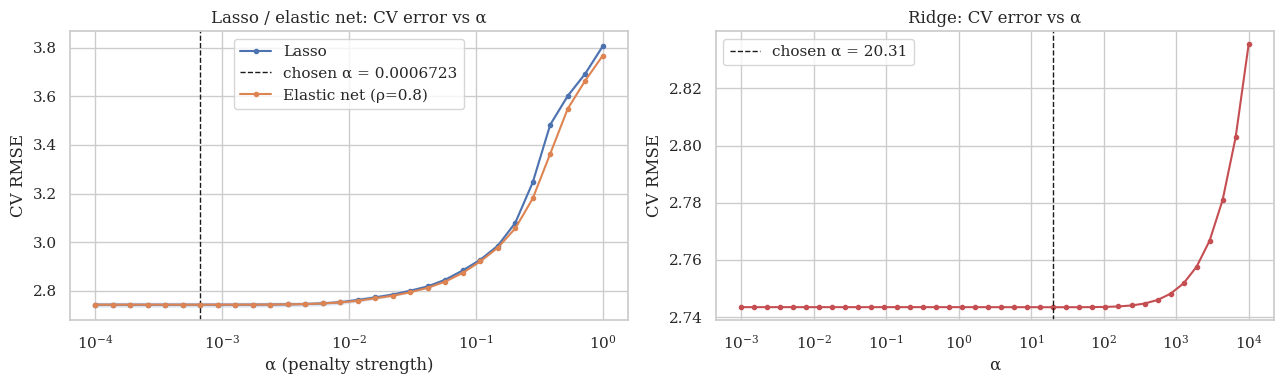

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
l = lasso["reg"]
m, s = np.sqrt(l.mse_path_).mean(axis=1), np.sqrt(l.mse_path_).std(axis=1)
axes[0].plot(l.alphas_, m, marker=".", label="Lasso"); axes[0].fill_between(l.alphas_, m - s, m + s, alpha=0.2)
axes[0].axvline(l.alpha_, ls="--", c="k", lw=1, label=f"chosen α = {l.alpha_:.4g}")
e = enet["reg"]
best_r = list(e.l1_ratio).index(e.l1_ratio_) if hasattr(e.l1_ratio, "__len__") else 0
axes[0].plot(e.alphas_[best_r] if e.alphas_.ndim > 1 else e.alphas_, np.sqrt(e.mse_path_[best_r]).mean(axis=1),
             marker=".", label=f"Elastic net (ρ={e.l1_ratio_})")
axes[0].set(xscale="log", xlabel="α (penalty strength)", ylabel="CV RMSE", title="Lasso / elastic net: CV error vs α"); axes[0].legend()

# Ridge: CV RMSE across the grid (manual 5-fold on the pre-transformed training data)
Z_tr = pre.transform(X_tr)
ridge_cv = [-cross_val_score(Ridge(alpha=a), Z_tr, y_tr, cv=CV, scoring="neg_root_mean_squared_error").mean() for a in ALPHAS_RIDGE]
axes[1].plot(ALPHAS_RIDGE, ridge_cv, marker=".", color="#C44E52")
axes[1].axvline(ridge["reg"].alpha_, ls="--", c="k", lw=1, label=f"chosen α = {ridge['reg'].alpha_:.4g}")
axes[1].set(xscale="log", xlabel="α", ylabel="CV RMSE", title="Ridge: CV error vs α"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "week2_cv_vs_alpha.png", dpi=200); plt.show()

## 5. Coefficient paths: shrinkage vs selection

Paths are computed on a 20,000-row training subsample for speed. As α grows, ridge coefficients shrink smoothly but none reach zero, while lasso coefficients drop out one by one.

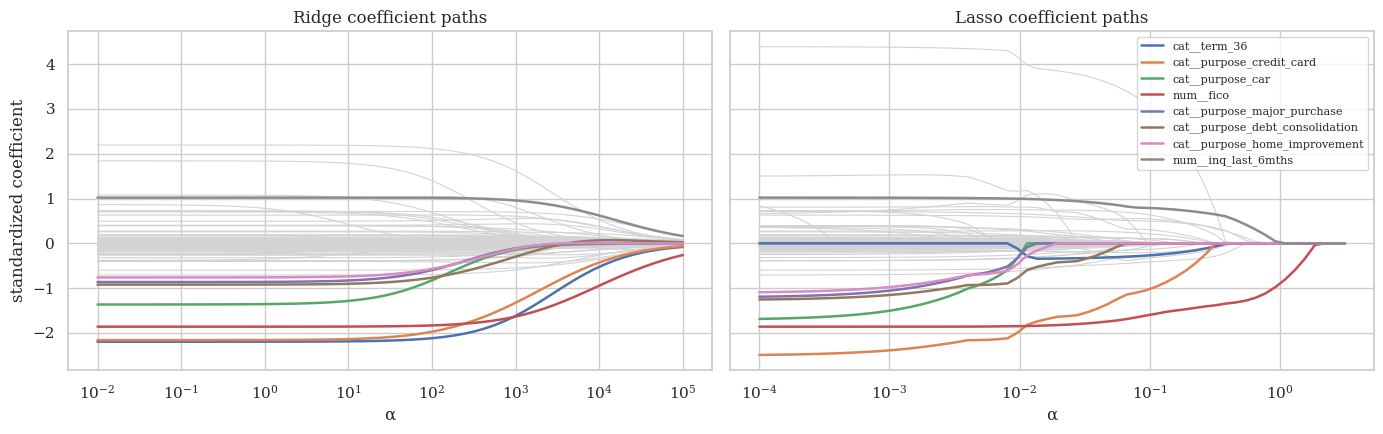

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
sub = rng.choice(len(Z_tr), size=min(20_000, len(Z_tr)), replace=False)
Zs, ys = Z_tr[sub], (y_tr.values[sub] - y_tr.values[sub].mean())
top = np.argsort(-np.abs(lasso["reg"].coef_))[:8]           # label the 8 largest lasso terms

alphas_l, coefs_l, _ = lasso_path(Zs, ys, alphas=np.logspace(-4, 0.5, 60))
coefs_r = np.array([Ridge(alpha=a).fit(Zs, ys).coef_ for a in np.logspace(-2, 5, 60)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
axes[0].plot(np.logspace(-2, 5, 60), coefs_r, color="lightgrey", lw=0.8)
axes[1].plot(alphas_l, coefs_l.T, color="lightgrey", lw=0.8)
for j in top:
    axes[0].plot(np.logspace(-2, 5, 60), coefs_r[:, j], lw=1.8, label=names[j])
    axes[1].plot(alphas_l, coefs_l[j], lw=1.8, label=names[j])
axes[0].set(xscale="log", title="Ridge coefficient paths", xlabel="α", ylabel="standardized coefficient")
axes[1].set(xscale="log", title="Lasso coefficient paths", xlabel="α")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "week2_coef_paths.png", dpi=200); plt.show()

## 6. Which terms matter?

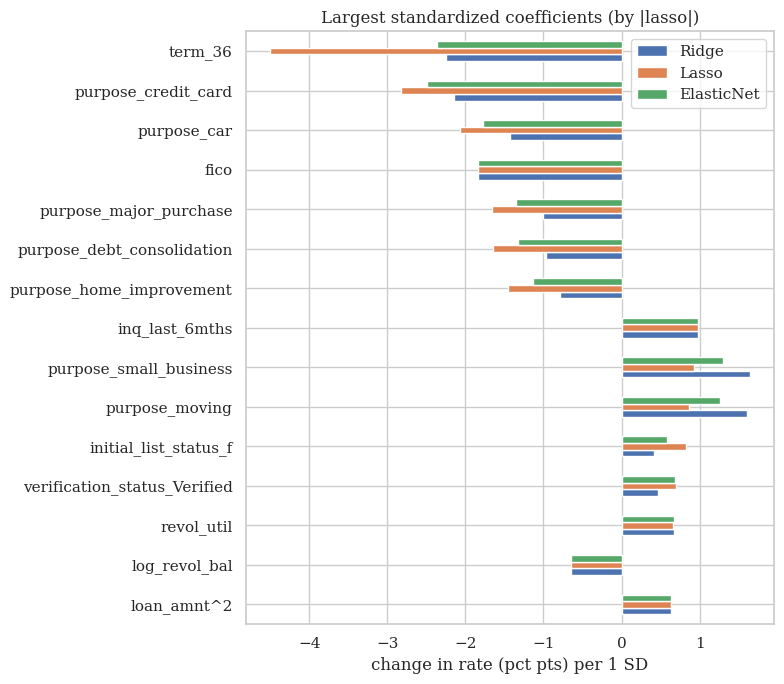

Lasso set 9 of 176 terms to exactly zero.
Squared/interaction terms kept by lasso: ['loan_amnt^2', 'loan_amnt log_annual_inc', 'loan_amnt dti', 'loan_amnt fico', 'loan_amnt inq_last_6mths', 'loan_amnt delinq_2yrs', 'loan_amnt open_acc', 'loan_amnt total_acc', 'loan_amnt revol_util', 'loan_amnt log_revol_bal', 'loan_amnt pub_rec', 'loan_amnt mort_acc', 'loan_amnt pub_rec_bankruptcies', 'loan_amnt credit_hist_years', 'loan_amnt emp_length_yrs', 'loan_amnt ever_delinq', 'log_annual_inc^2', 'log_annual_inc dti', 'log_annual_inc fico', 'log_annual_inc inq_last_6mths', 'log_annual_inc delinq_2yrs', 'log_annual_inc open_acc', 'log_annual_inc total_acc', 'log_annual_inc revol_util', 'log_annual_inc log_revol_bal', 'log_annual_inc mort_acc', 'log_annual_inc pub_rec_bankruptcies', 'log_annual_inc credit_hist_years', 'log_annual_inc emp_length_yrs', 'log_annual_inc ever_delinq', 'dti^2', 'dti fico', 'dti inq_last_6mths', 'dti delinq_2yrs', 'dti open_acc', 'dti total_acc', 'dti revol_util', 'dti l

In [9]:
coef = pd.DataFrame({
    "OLS": ols_poly["reg"].coef_, "Ridge": ridge["reg"].coef_,
    "Lasso": lasso["reg"].coef_, "ElasticNet": enet["reg"].coef_,
}, index=[n.replace("num__", "").replace("cat__", "") for n in names])
top15 = coef["Lasso"].abs().sort_values(ascending=False).head(15).index
ax = coef.loc[top15[::-1], ["Ridge", "Lasso", "ElasticNet"]].plot.barh(figsize=(8, 7))
ax.set(title="Largest standardized coefficients (by |lasso|)", xlabel="change in rate (pct pts) per 1 SD")
plt.tight_layout(); plt.show()

zeroed = coef.index[coef["Lasso"] == 0]
print(f"Lasso set {len(zeroed)} of {len(coef)} terms to exactly zero.")
print("Squared/interaction terms kept by lasso:",
      [i for i in coef.index[(coef['Lasso'] != 0)] if (' ' in i or '^2' in i)])
print("Terms set to zero:", list(zeroed))
print("Largest |lasso| terms:", coef["Lasso"].abs().sort_values(ascending=False).head(8).round(3).to_dict())

## 7. Conclusions

**Did regularization help?** No. On the 176-term expanded model, OLS, ridge, lasso, and elastic net all have CV RMSE 2.743 and test RMSE 2.808–2.809. Cross-validation chose penalties close to zero: lasso α = 6.7 × 10⁻⁴ (7th-smallest of the 30 grid values) and elastic net α = 1.9 × 10⁻⁴ with ρ = 0.8 (3rd-smallest). Ridge chose α = 20, but with 140,000 rows that shrinks almost nothing, so its predictions match OLS. With about 800 training rows per term, OLS is already stable and there is nothing for the penalty to fix.

**Overfitting check.** The expanded OLS has train RMSE 2.738 against CV RMSE 2.743, a gap of 0.006, so it is not overfitting. Test RMSE is about 0.07 higher than CV, but the check in Section 3 shows why: one test loan has revol_util = 892% (the training maximum is 178%), and the squared and interaction terms turn it into a predicted rate of 151%. Without the 5 largest errors, test RMSE is 2.748, essentially the CV value. A real deployment would need to flag impossible utilization values the way Week 1 handles DTI.

**Selection.** Lasso is not selecting features here. It zeroed only 9 of 176 terms, and 8 of those are categorical dummy levels, mostly redundant ones: one-hot encoding keeps every level, so one level per variable adds nothing beyond the intercept (e.g. `application_type_Individual`, `initial_list_status_w`). The only polynomial term dropped was `log_annual_inc × pub_rec`.

**Expanded vs. linear terms.** The squares and interactions help a little: test RMSE falls from 2.857 (linear OLS) to 2.808. This agrees with Week 1, where curvature in FICO and DTI and the term interactions added a small but significant amount.

**Which terms matter.** The largest lasso coefficients are loan term, several loan purposes (credit card, car, major purchase, debt consolidation, home improvement), FICO, and recent credit inquiries. These are the attributes LendingClub priced most heavily. Weeks 4–6 test whether the same attributes predict actual charge-off.
